In [1]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.detection import detect_current_sheets
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [2]:
#Defining all the required functions

#Fourier Transform Functions


#Defining constants
dx = 0.0625
dy = 0.0625





Analysing 11 snapshots across 11 workers ...
IMF 1
IMF 2
IMF 3
IMF 4
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so
t=245: 197 sheets
t=220: 208 sheets
t=230: 212 sheets
t=235: 206 sheets
t=240: 214 sheets
t=225: 215 sheets
t=210: 235 sheets
t=215: 231 sheets
t=205: 242 sheets
t=250: 205 sheets
t=200: 244 sheets

pooled 2409 sheets from 11 snapshots


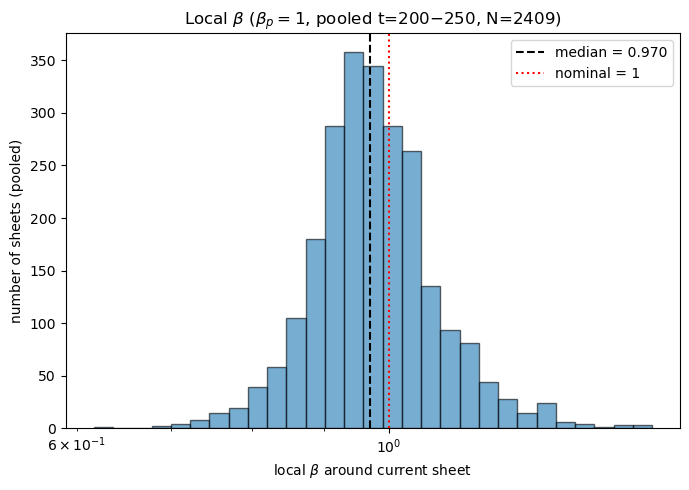


--- thickness statistics in beta bins (pooled) ---
          beta range      N   median thick (d_i)   mean thick (d_i)
  0.617-  0.741     14                0.673              0.733
  0.741-  0.889    344                0.729              0.789
  0.889-  1.068   1676                0.707              0.755
  1.068-  1.282    338                0.729              0.755
  1.282-  1.539     36                0.770              0.811


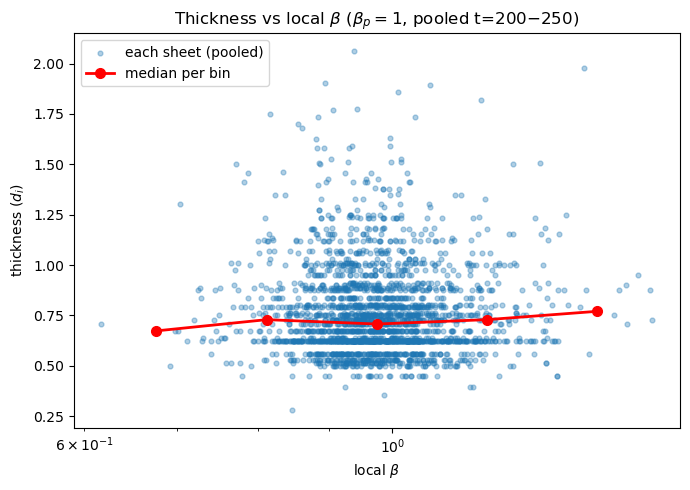


--- overall (pooled) statistics ---
local beta : median = 0.970, mean = 0.982
thickness  : median = 0.707, mean = 0.760 d_i

Everything saved in:  cs_beta_pooled_beta1_t200-250/


In [4]:
# ============================================================
#  Current sheets: local beta + thickness, POOLED over snapshots
#  ------------------------------------------------------------
#  For every snapshot in TIMES it detects the sheets and measures, per sheet,
#  the thickness and the local beta in a rectangle around it. All sheets from
#  all snapshots are then POOLED into one dataset, and we save:
#    - histogram of local beta
#    - per-sheet table (with the snapshot time)  +  beta-binned summary table
#    - scatter plot of thickness vs local beta (with binned medians)
#    - the pooled arrays as .npz (so you can re-analyse without recomputing)
#
#  Needs from your session: iterative_filtering3D, partial_x_fft, partial_y_fft,
#                            detect_current_sheets
# ============================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

# -----------------------------
# SETTINGS
# -----------------------------
beta      = 1                          # which run: 0.0625, 0.25, 1, 4, 16
times     = list(range(200, 251, 5))   # 200, 205, ..., 250  (pooled together)
sim_tag   = "ApJ"
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"

cache_dir = str(CACHE / "filtered_cache_Jz")
out_dir   = str(RESULTS / f"cs_beta_pooled_beta{beta}_t{times[0]}-{times[-1]}")

px_per_di = 16.0                       # pixels per ion inertial length
box_pad   = 5                          # padding (px) of the rectangle around each sheet
n_workers = min(len(times), os.cpu_count() or 1)
dx = dy   = 0.0625

P_PAR_TAG = "Ppar1"                    # proton parallel  pressure tag
P_PER_TAG = "Pper1"                    # proton perpendicular pressure tag

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)


def filter_params(b):
    if b == 0.0625: return 3, 2.0
    if b == 0.25:   return 3, 2.3
    if b == 1:      return 3, 2.5
    if b == 4:      return 3, 2.7
    return 3, 3.0


def load(tag, time):
    with h5py.File(f"{base_path}{tag}_{sim_tag}_t{time}.h5", "r") as f:
        return f["DS1"][:].T


# ============================================================
# One snapshot: returns (time, thickness_array_di, local_beta_array)
# (same logic as the single-snapshot script, no plotting)
# ============================================================
def analyze_snapshot(time):
    # --- beta field (RAW fields) ---
    Bx, By, Bz = load("Bx", time), load("By", time), load("Bz", time)
    P_mag = 0.5 * (Bx**2 + By**2 + Bz**2)
    P_par  = load(P_PAR_TAG, time)
    P_perp = load(P_PER_TAG, time)
    P_scalar = (P_par + 2.0 * P_perp) / 3.0
    beta_field = P_scalar / P_mag

    # --- detect sheets (filtered B, cached) ---
    n_iter, Xi = filter_params(beta)
    cache_file = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache_file):
        d = np.load(cache_file)
        Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        Bx_f, By_f, Bz_f = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache_file, Bx=Bx_f, By=By_f, Bz=Bz_f)

    Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    mask = morphology.remove_small_objects(mask.astype(bool), min_size=500).astype(int)

    labeled = measure.label(mask, connectivity=2)
    n_sheets = labeled.max()
    all_sheets_mask = labeled > 0

    # --- per sheet: thickness + local beta in a rectangle around it ---
    thick, lbeta = [], []
    for k in range(1, n_sheets + 1):
        region = (labeled == k)

        dist = ndi.distance_transform_edt(region)
        thick_di = (2 * dist.max()) / px_per_di

        xs_r, ys_r = np.where(region)
        bx0 = max(0, xs_r.min() - box_pad)
        bx1 = min(beta_field.shape[0], xs_r.max() + box_pad + 1)
        by0 = max(0, ys_r.min() - box_pad)
        by1 = min(beta_field.shape[1], ys_r.max() + box_pad + 1)
        box_region = np.zeros_like(region)
        box_region[bx0:bx1, by0:by1] = True
        box_region = box_region & ~all_sheets_mask
        if box_region.sum() < 20:
            continue

        thick.append(thick_di)
        lbeta.append(float(np.median(beta_field[box_region])))

    return time, np.array(thick), np.array(lbeta)


# ============================================================
# STEP 1. Run every snapshot (parallel), then POOL all sheets
# ============================================================
records = []
if n_workers == 1:
    for t in times:
        try:
            records.append(analyze_snapshot(t))
            print(f"t={t}: {len(records[-1][1])} sheets", flush=True)
        except FileNotFoundError:
            print(f"t={t}: missing file, skipped", flush=True)
else:
    ctx = mp.get_context("fork")
    print(f"Analysing {len(times)} snapshots across {n_workers} workers ...", flush=True)
    with ProcessPoolExecutor(max_workers=n_workers, mp_context=ctx) as ex:
        futs = {ex.submit(analyze_snapshot, t): t for t in times}
        for fut in as_completed(futs):
            t = futs[fut]
            try:
                records.append(fut.result())
                print(f"t={t}: {len(records[-1][1])} sheets", flush=True)
            except FileNotFoundError:
                print(f"t={t}: missing file, skipped", flush=True)

# pool every sheet from every snapshot into flat arrays
pooled_time, pooled_thick, pooled_beta = [], [], []
for time, th, lb in records:
    pooled_time.extend([time] * len(th))
    pooled_thick.extend(th)
    pooled_beta.extend(lb)

times_arr  = np.array(pooled_time)
thickness  = np.array(pooled_thick)
local_beta = np.array(pooled_beta)
print(f"\npooled {len(thickness)} sheets from {len(records)} snapshots", flush=True)
if len(local_beta) == 0:
    raise SystemExit("No sheets pooled (check paths / times).")

# save the pooled arrays for later re-analysis
np.savez_compressed(f"{out_dir}/pooled_beta_thickness.npz",
                    time=times_arr, thickness_di=thickness, local_beta=local_beta)


# ============================================================
# STEP 2. Histogram of pooled local beta
# ============================================================
plt.figure(figsize=(7, 5))
plt.hist(local_beta,
         bins=np.logspace(np.log10(local_beta.min()), np.log10(local_beta.max()), 30),
         alpha=0.6, edgecolor="black")
plt.axvline(np.median(local_beta), color="black", linestyle="--",
            label=f"median = {np.median(local_beta):.3f}")
plt.axvline(beta, color="red", linestyle=":", label=f"nominal = {beta}")
plt.xscale("log")
plt.xlabel(r"local $\beta$ around current sheet")
plt.ylabel("number of sheets (pooled)")
plt.title(rf"Local $\beta$ ($\beta_p={beta}$, pooled t={times[0]}$-${times[-1]}, N={len(local_beta)})")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_local_beta.png", dpi=300)
plt.show()


# ============================================================
# STEP 3. beta vs thickness: per-sheet table, summary table, scatter
# ============================================================
# 3a. per-sheet table (with the snapshot time)
with open(f"{out_dir}/beta_vs_thickness.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["time", "thickness_di", "local_beta"])
    for i in range(len(thickness)):
        w.writerow([int(times_arr[i]), thickness[i], local_beta[i]])

# 3b. summary: split pooled sheets into beta bins, thickness in each
bin_edges = np.logspace(np.log10(local_beta.min()), np.log10(local_beta.max()), 6)  # 5 bins
print("\n--- thickness statistics in beta bins (pooled) ---")
print(f"{'beta range':>20} {'N':>6} {'median thick (d_i)':>20} {'mean thick (d_i)':>18}")
summary_rows = []
bin_centres, bin_med_thick = [], []
for i in range(len(bin_edges) - 1):
    lo, hi = bin_edges[i], bin_edges[i + 1]
    sel = (local_beta >= lo) & (local_beta < hi)
    if sel.sum() == 0:
        continue
    med_t, mean_t = np.median(thickness[sel]), np.mean(thickness[sel])
    print(f"{lo:7.3f}-{hi:7.3f} {sel.sum():>6} {med_t:>20.3f} {mean_t:>18.3f}")
    summary_rows.append([lo, hi, int(sel.sum()), med_t, mean_t])
    bin_centres.append(np.sqrt(lo * hi))
    bin_med_thick.append(med_t)

with open(f"{out_dir}/beta_thickness_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["beta_lo", "beta_hi", "n_sheets", "median_thickness_di", "mean_thickness_di"])
    w.writerows(summary_rows)

# 3c. scatter of thickness vs local beta, with binned medians on top
plt.figure(figsize=(7, 5))
plt.scatter(local_beta, thickness, s=12, alpha=0.35, label="each sheet (pooled)")
plt.plot(bin_centres, bin_med_thick, "o-", color="red", lw=2, ms=7, label="median per bin")
plt.xscale("log")
plt.xlabel(r"local $\beta$")
plt.ylabel(r"thickness $(d_i)$")
plt.title(rf"Thickness vs local $\beta$ ($\beta_p={beta}$, pooled t={times[0]}$-${times[-1]})")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_beta.png", dpi=300)
plt.show()

# ---- final numbers ----
print("\n--- overall (pooled) statistics ---")
print(f"local beta : median = {np.median(local_beta):.3f}, mean = {np.mean(local_beta):.3f}")
print(f"thickness  : median = {np.median(thickness):.3f}, mean = {np.mean(thickness):.3f} d_i")
print(f"\nEverything saved in:  {out_dir}/")

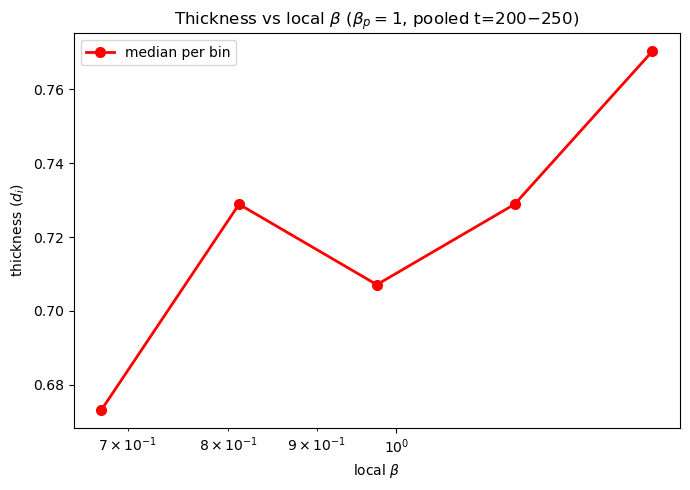

In [6]:
plt.figure(figsize=(7, 5))
# plt.scatter(local_beta, thickness, s=12, alpha=0.35, label="each sheet (pooled)")
plt.plot(bin_centres, bin_med_thick, "o-", color="red", lw=2, ms=7, label="median per bin")
plt.xscale("log")
plt.xlabel(r"local $\beta$")
plt.ylabel(r"thickness $(d_i)$")
plt.title(rf"Thickness vs local $\beta$ ($\beta_p={beta}$, pooled t={times[0]}$-${times[-1]})")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_beta.png", dpi=300)
plt.show()

Analysing 55 (beta,time) snapshots across 55 workers ...
IMF 1
IMF 1
IMF 2
IMF 2
IMF 3
IMF 3
IMF 4
IMF 4
IMF 1
input mask not integer, making it so
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so
IMF 4
input mask not integer, making it so
IMF 1
input mask not integer, making it so
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so
IMF 4
input mask not integer, making it so
beta=16, t=225: 79 sheets
beta=16, t=245: 99 sheets
beta=16, t=240: 100 sheets
beta=16, t=235: 102 sheets
beta=16, t=205: 105 sheets
beta=16, t=210: 106 sheets
beta=16, t=230: 108 sheets
beta=16, t=220: 109 

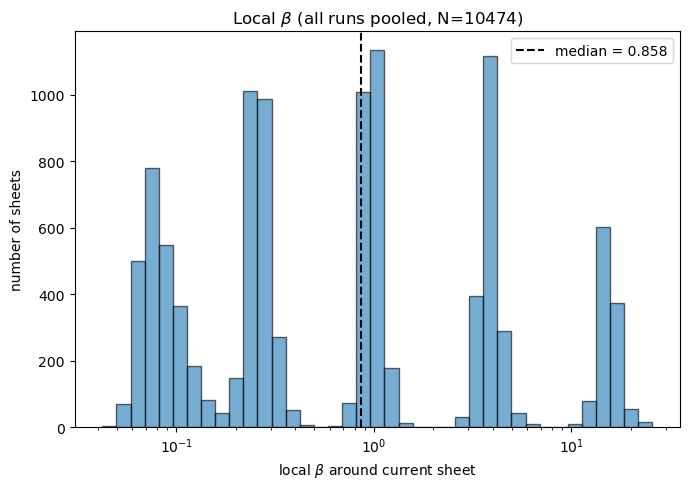

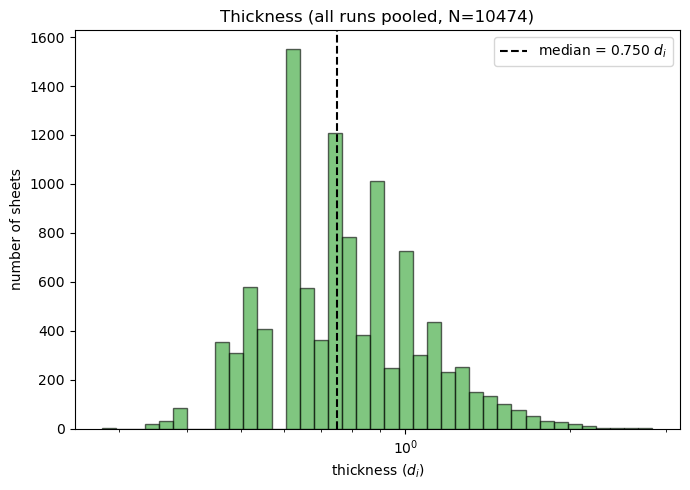

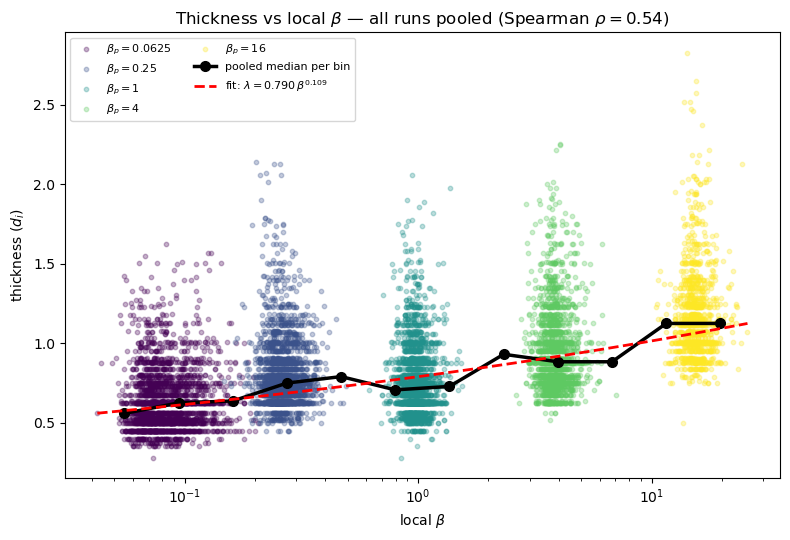


--- pooled sample ---
total sheets           : 10474
local beta  : median = 0.858  (range 0.0422-25.8)
thickness   : median = 0.750 d_i
power-law fit          : lambda = 0.790 * beta_local^0.109
Spearman rho (thick,lb): 0.541  (p=0)

--- per-run median local beta vs nominal (calibration glance) ---
  beta_p       N  median local beta
  0.0625    2569              0.080
    0.25    2482              0.260
       1    2409              0.970
       4    1882              3.833
      16    1132             15.353

Everything saved in:  cs_beta_pooled_ALL_t200-250/


In [7]:
# ============================================================
#  Current sheets: thickness vs LOCAL beta
#  ALL nominal-beta runs pooled into ONE dataset
#  ------------------------------------------------------------
#  For every (beta, time) it detects the sheets and measures, per sheet,
#  the thickness and the local beta in a rectangle around it. Every sheet
#  from every run and every snapshot is pooled into a single sample, then:
#     - histogram of local beta (pooled)
#     - histogram of thickness  (pooled)
#     - thickness vs local beta : scatter (coloured by run) + pooled binned
#       medians + a single power-law fit  lambda = a * beta_local^b
#     - pooled CSV + .npz, binned summary CSV, Spearman correlation
#
#  Needs from your session: iterative_filtering3D, partial_x_fft,
#                           partial_y_fft, detect_current_sheets
# ============================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
from scipy.stats import spearmanr
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

# -----------------------------
# SETTINGS
# -----------------------------
BETAS     = [0.0625, 0.25, 1, 4, 16]      # runs to pool together
TIMES     = list(range(200, 251, 5))       # snapshots per run
sim_tag   = "ApJ"
base_root = str(DATA_ROOT)

cache_dir = str(CACHE / "filtered_cache_Jz")
out_dir   = str(RESULTS / f"cs_beta_pooled_ALL_t{TIMES[0]}-{TIMES[-1]}")

px_per_di = 16.0                           # pixels per ion inertial length
box_pad   = 5                              # padding (px) of the rectangle around each sheet
dx = dy   = 0.0625

P_PAR_TAG = "Ppar1"                        # proton parallel  pressure tag
P_PER_TAG = "Pper1"                        # proton perpendicular pressure tag

THREADS_PER_WORKER = 1                     # cap BLAS threads per worker
N_BINS_MED = 12                            # local-beta bins for the pooled median relation
MIN_PER_BIN = 10                           # ignore bins with fewer sheets than this in the fit

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)


def filter_params(b):
    if b == 0.0625: return 3, 2.0
    if b == 0.25:   return 3, 2.3
    if b == 1:      return 3, 2.5
    if b == 4:      return 3, 2.7
    return 3, 3.0


def base_path(beta):
    return f"{base_root}/beta_p_{beta}/beta_e_1/"


def load(tag, beta, time):
    with h5py.File(f"{base_path(beta)}{tag}_{sim_tag}_t{time}.h5", "r") as f:
        return f["DS1"][:].T


def _init_worker(n_threads):
    try:
        from threadpoolctl import threadpool_limits
        threadpool_limits(n_threads)
    except Exception:
        pass


# ============================================================
# One (beta, time) snapshot -> (beta, time, thickness_di[], local_beta[])
# ============================================================
def analyze_snapshot(beta, time):
    Bx, By, Bz = load("Bx", beta, time), load("By", beta, time), load("Bz", beta, time)
    P_mag = 0.5 * (Bx**2 + By**2 + Bz**2)
    P_par  = load(P_PAR_TAG, beta, time)
    P_perp = load(P_PER_TAG, beta, time)
    P_scalar = (P_par + 2.0 * P_perp) / 3.0
    beta_field = P_scalar / P_mag

    n_iter, Xi = filter_params(beta)
    cache_file = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache_file):
        d = np.load(cache_file)
        Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        Bx_f, By_f, Bz_f = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache_file, Bx=Bx_f, By=By_f, Bz=Bz_f)

    Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    mask = morphology.remove_small_objects(mask.astype(bool), min_size=500).astype(int)

    labeled = measure.label(mask, connectivity=2)
    n_sheets = labeled.max()
    all_sheets_mask = labeled > 0

    thick, lbeta = [], []
    for k in range(1, n_sheets + 1):
        region = (labeled == k)

        dist = ndi.distance_transform_edt(region)
        thick_di = (2 * dist.max()) / px_per_di

        xs_r, ys_r = np.where(region)
        bx0 = max(0, xs_r.min() - box_pad)
        bx1 = min(beta_field.shape[0], xs_r.max() + box_pad + 1)
        by0 = max(0, ys_r.min() - box_pad)
        by1 = min(beta_field.shape[1], ys_r.max() + box_pad + 1)
        box_region = np.zeros_like(region)
        box_region[bx0:bx1, by0:by1] = True
        box_region = box_region & ~all_sheets_mask
        if box_region.sum() < 20:
            continue

        thick.append(thick_di)
        lbeta.append(float(np.median(beta_field[box_region])))

    return beta, time, np.array(thick), np.array(lbeta)


# ============================================================
# STEP 1. Run every (beta, time) in parallel, pool EVERYTHING together
# ============================================================
tasks = [(b, t) for b in BETAS for t in TIMES]
n_workers = min(len(tasks), os.cpu_count() or 1)

nominal_beta, snap_time, thickness, local_beta = [], [], [], []

def _store(res):
    b, t, th, lb = res
    nominal_beta.extend([b] * len(th))
    snap_time.extend([t] * len(th))
    thickness.extend(th)
    local_beta.extend(lb)
    print(f"beta={b}, t={t}: {len(th)} sheets", flush=True)

if n_workers == 1:
    for b, t in tasks:
        try:
            _store(analyze_snapshot(b, t))
        except FileNotFoundError:
            print(f"beta={b}, t={t}: missing file, skipped", flush=True)
else:
    ctx = mp.get_context("fork")
    print(f"Analysing {len(tasks)} (beta,time) snapshots across {n_workers} workers ...", flush=True)
    with ProcessPoolExecutor(max_workers=n_workers, mp_context=ctx,
                             initializer=_init_worker, initargs=(THREADS_PER_WORKER,)) as ex:
        futs = {ex.submit(analyze_snapshot, b, t): (b, t) for b, t in tasks}
        for fut in as_completed(futs):
            b, t = futs[fut]
            try:
                _store(fut.result())
            except FileNotFoundError:
                print(f"beta={b}, t={t}: missing file, skipped", flush=True)

nominal_beta = np.array(nominal_beta)
snap_time    = np.array(snap_time)
thickness    = np.array(thickness)
local_beta   = np.array(local_beta)
print(f"\npooled {len(thickness)} sheets total (all runs, all snapshots)", flush=True)
if len(thickness) == 0:
    raise SystemExit("No sheets pooled (check paths/times).")

# pooled dataset (nominal beta kept only as a per-sheet tag for provenance)
np.savez_compressed(f"{out_dir}/pooled_all.npz",
                    nominal_beta=nominal_beta, time=snap_time,
                    thickness_di=thickness, local_beta=local_beta)
with open(f"{out_dir}/pooled_all.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["nominal_beta", "time", "thickness_di", "local_beta"])
    for i in range(len(thickness)):
        w.writerow([nominal_beta[i], int(snap_time[i]), thickness[i], local_beta[i]])


# ============================================================
# STEP 2. Pooled distributions
# ============================================================
plt.figure(figsize=(7, 5))
plt.hist(local_beta,
         bins=np.logspace(np.log10(local_beta.min()), np.log10(local_beta.max()), 40),
         alpha=0.6, edgecolor="black")
plt.axvline(np.median(local_beta), color="black", linestyle="--",
            label=f"median = {np.median(local_beta):.3f}")
plt.xscale("log")
plt.xlabel(r"local $\beta$ around current sheet"); plt.ylabel("number of sheets")
plt.title(rf"Local $\beta$ (all runs pooled, N={len(local_beta)})")
plt.legend(); plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_local_beta_pooled.png", dpi=300); plt.show()

plt.figure(figsize=(7, 5))
plt.hist(thickness,
         bins=np.logspace(np.log10(thickness.min()), np.log10(thickness.max()), 40),
         alpha=0.6, edgecolor="black", color="tab:green")
plt.axvline(np.median(thickness), color="black", linestyle="--",
            label=f"median = {np.median(thickness):.3f} $d_i$")
plt.xscale("log")
plt.xlabel(r"thickness $(d_i)$"); plt.ylabel("number of sheets")
plt.title(rf"Thickness (all runs pooled, N={len(thickness)})")
plt.legend(); plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_thickness_pooled.png", dpi=300); plt.show()


# ============================================================
# STEP 3. Thickness vs local beta (pooled) + power-law fit
# ============================================================
# pooled binned medians over the full local-beta range
edges = np.logspace(np.log10(local_beta.min()), np.log10(local_beta.max()), N_BINS_MED + 1)
cen, med, cnt = [], [], []
summary_rows = []
for i in range(N_BINS_MED):
    lo, hi = edges[i], edges[i + 1]
    sel = (local_beta >= lo) & (local_beta < hi)
    if sel.sum() == 0:
        continue
    c = np.sqrt(lo * hi)
    cen.append(c); med.append(np.median(thickness[sel])); cnt.append(int(sel.sum()))
    summary_rows.append([lo, hi, int(sel.sum()),
                         np.median(thickness[sel]), np.mean(thickness[sel])])
cen, med, cnt = np.array(cen), np.array(med), np.array(cnt)

with open(f"{out_dir}/binned_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["localbeta_lo", "localbeta_hi", "n_sheets",
                "median_thickness_di", "mean_thickness_di"])
    w.writerows(summary_rows)

# power-law fit  thickness = a * local_beta^b  (on bins with enough sheets)
fit_ok = cnt >= MIN_PER_BIN
a = b = np.nan
if fit_ok.sum() >= 2:
    b, logA = np.polyfit(np.log10(cen[fit_ok]), np.log10(med[fit_ok]), 1)
    a = 10 ** logA

# Spearman rank correlation on the full pooled sample
rho, pval = spearmanr(local_beta, thickness)

# discrete colour per run, just to show provenance in the scatter
present = [bb for bb in BETAS if np.any(nominal_beta == bb)]
colors = {bb: plt.cm.viridis(i / max(1, len(present) - 1)) for i, bb in enumerate(present)}

plt.figure(figsize=(8, 5.5))
for bb in present:
    m = nominal_beta == bb
    plt.scatter(local_beta[m], thickness[m], s=10, alpha=0.30,
                color=colors[bb], label=fr"$\beta_p={bb}$")
plt.plot(cen, med, "o-", color="black", lw=2.5, ms=7, label="pooled median per bin")
if np.isfinite(b):
    xx = np.logspace(np.log10(local_beta.min()), np.log10(local_beta.max()), 60)
    plt.plot(xx, a * xx**b, "--", color="red", lw=2,
             label=fr"fit: $\lambda = {a:.3f}\,\beta^{{{b:.3f}}}$")
plt.xscale("log")
plt.xlabel(r"local $\beta$"); plt.ylabel(r"thickness $(d_i)$")
plt.title(rf"Thickness vs local $\beta$ — all runs pooled (Spearman $\rho={rho:.2f}$)")
plt.legend(fontsize=8, ncol=2); plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_localbeta_pooled.png", dpi=300); plt.show()


# ============================================================
# Summary (incl. a per-run calibration glance: median local beta vs nominal)
# ============================================================
print("\n--- pooled sample ---")
print(f"total sheets           : {len(thickness)}")
print(f"local beta  : median = {np.median(local_beta):.3f}  (range {local_beta.min():.3g}-{local_beta.max():.3g})")
print(f"thickness   : median = {np.median(thickness):.3f} d_i")
if np.isfinite(b):
    print(f"power-law fit          : lambda = {a:.3f} * beta_local^{b:.3f}")
print(f"Spearman rho (thick,lb): {rho:.3f}  (p={pval:.2g})")

print("\n--- per-run median local beta vs nominal (calibration glance) ---")
print(f"{'beta_p':>8} {'N':>7} {'median local beta':>18}")
for bb in present:
    m = nominal_beta == bb
    print(f"{bb:>8} {m.sum():>7} {np.median(local_beta[m]):>18.3f}")
print(f"\nEverything saved in:  {out_dir}/")

In [3]:
# %% ==========================================================================
#  CELL 1 — COMPUTATION  (run ONCE; heavy parallel analysis + pooling)
# ============================================================================
#  Current sheets: local PROTON beta + thickness, POOLED over snapshots.
#  One run (proton beta = `beta`, electron beta = 1 fixed). For every snapshot
#  in `times` it detects sheets and measures, per sheet, the thickness and the
#  local proton beta in a rectangle around it; all sheets from all snapshots are
#  pooled. The local beta is built from the proton pressures (Ppar1/Pper1), so
#  it is beta_p.
#
#  Produces the in-memory arrays used by CELL 2 (also saved to
#  pooled_beta_thickness.npz):   times_arr, thickness, local_beta_p
#  Re-run this cell only when the data or detection settings change.
#
#  Needs from your session: iterative_filtering3D, partial_x_fft, partial_y_fft,
#                           detect_current_sheets
# ============================================================================

import os
import csv
import numpy as np
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

# -----------------------------
# SETTINGS
# -----------------------------
beta      = 1                          # which run (proton beta): 0.0625, 0.25, 1, 4, 16
times     = list(range(200, 251, 5))   # 200, 205, ..., 250  (pooled together)
sim_tag   = "ApJ"
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"

cache_dir = str(CACHE / "filtered_cache_Jz")
out_dir   = str(RESULTS / f"cs_beta_pooled_beta{beta}_t{times[0]}-{times[-1]}")

px_per_di = 16.0                       # pixels per ion inertial length
box_pad   = 5                          # padding (px) of the rectangle around each sheet
n_workers = min(len(times), os.cpu_count() or 1)
dx = dy   = 0.0625

P_PAR_TAG = "Ppar1"                    # proton parallel  pressure tag
P_PER_TAG = "Pper1"                    # proton perpendicular pressure tag

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)


def filter_params(b):
    if b == 0.0625: return 3, 2.0
    if b == 0.25:   return 3, 2.3
    if b == 1:      return 3, 2.5
    if b == 4:      return 3, 2.7
    return 3, 3.0


def load(tag, time):
    with h5py.File(f"{base_path}{tag}_{sim_tag}_t{time}.h5", "r") as f:
        return f["DS1"][:].T


# ============================================================
# One snapshot: returns (time, thickness_array_di, local_beta_p_array)
# ============================================================
def analyze_snapshot(time):
    # --- proton beta field (RAW fields, proton pressures) ---
    Bx, By, Bz = load("Bx", time), load("By", time), load("Bz", time)
    P_mag = 0.5 * (Bx**2 + By**2 + Bz**2)
    P_par  = load(P_PAR_TAG, time)
    P_perp = load(P_PER_TAG, time)
    P_scalar = (P_par + 2.0 * P_perp) / 3.0
    beta_p_field = P_scalar / P_mag

    # --- detect sheets (filtered B, cached) ---
    n_iter, Xi = filter_params(beta)
    cache_file = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache_file):
        d = np.load(cache_file)
        Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        Bx_f, By_f, Bz_f = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache_file, Bx=Bx_f, By=By_f, Bz=Bz_f)

    Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    mask = morphology.remove_small_objects(mask.astype(bool), min_size=500).astype(int)

    labeled = measure.label(mask, connectivity=2)
    n_sheets = labeled.max()
    all_sheets_mask = labeled > 0

    # --- per sheet: thickness + local proton beta in a rectangle around it ---
    thick, lbeta_p = [], []
    for k in range(1, n_sheets + 1):
        region = (labeled == k)

        dist = ndi.distance_transform_edt(region)
        thick_di = (2 * dist.max()) / px_per_di

        xs_r, ys_r = np.where(region)
        bx0 = max(0, xs_r.min() - box_pad)
        bx1 = min(beta_p_field.shape[0], xs_r.max() + box_pad + 1)
        by0 = max(0, ys_r.min() - box_pad)
        by1 = min(beta_p_field.shape[1], ys_r.max() + box_pad + 1)
        box_region = np.zeros_like(region)
        box_region[bx0:bx1, by0:by1] = True
        box_region = box_region & ~all_sheets_mask
        if box_region.sum() < 20:
            continue

        thick.append(thick_di)
        lbeta_p.append(float(np.median(beta_p_field[box_region])))

    return time, np.array(thick), np.array(lbeta_p)


# ============================================================
# Run every snapshot (parallel), then POOL all sheets
# ============================================================
records = []
if n_workers == 1:
    for t in times:
        try:
            records.append(analyze_snapshot(t))
            print(f"t={t}: {len(records[-1][1])} sheets", flush=True)
        except FileNotFoundError:
            print(f"t={t}: missing file, skipped", flush=True)
else:
    ctx = mp.get_context("fork")
    print(f"Analysing {len(times)} snapshots across {n_workers} workers ...", flush=True)
    with ProcessPoolExecutor(max_workers=n_workers, mp_context=ctx) as ex:
        futs = {ex.submit(analyze_snapshot, t): t for t in times}
        for fut in as_completed(futs):
            t = futs[fut]
            try:
                records.append(fut.result())
                print(f"t={t}: {len(records[-1][1])} sheets", flush=True)
            except FileNotFoundError:
                print(f"t={t}: missing file, skipped", flush=True)

# pool every sheet from every snapshot into flat arrays
pooled_time, pooled_thick, pooled_beta_p = [], [], []
for time, th, lb in records:
    pooled_time.extend([time] * len(th))
    pooled_thick.extend(th)
    pooled_beta_p.extend(lb)

times_arr    = np.array(pooled_time)
thickness    = np.array(pooled_thick)
local_beta_p = np.array(pooled_beta_p)
print(f"\npooled {len(thickness)} sheets from {len(records)} snapshots", flush=True)
if len(local_beta_p) == 0:
    raise SystemExit("No sheets pooled (check paths / times).")

# save the pooled arrays for later re-analysis
np.savez_compressed(f"{out_dir}/pooled_beta_thickness.npz",
                    time=times_arr, thickness_di=thickness, local_beta_p=local_beta_p)
print(f"saved pooled data -> {out_dir}/pooled_beta_thickness.npz", flush=True)

Analysing 11 snapshots across 11 workers ...
t=245: 197 sheets
t=250: 205 sheets
t=235: 206 sheets
t=220: 208 sheets
t=230: 212 sheets
t=240: 214 sheets
t=225: 215 sheets
t=215: 231 sheets
t=210: 235 sheets
t=200: 244 sheets
t=205: 242 sheets

pooled 2409 sheets from 11 snapshots
saved pooled data -> cs_beta_pooled_beta1_t200-250/pooled_beta_thickness.npz


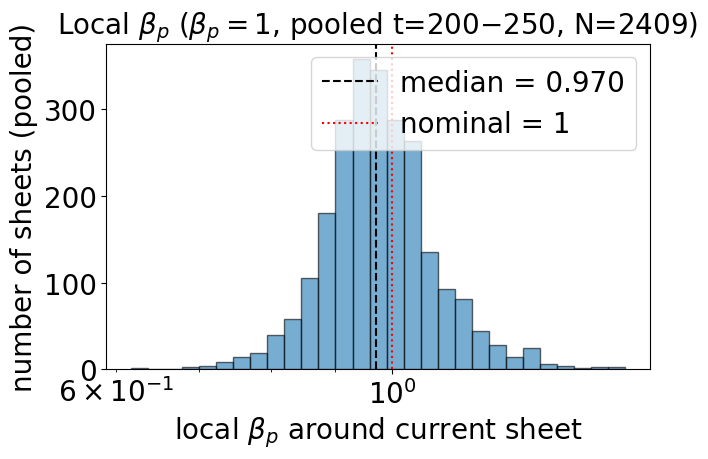


--- thickness statistics in beta_p bins (pooled) ---
        beta_p range      N   median thick (d_i)   mean thick (d_i)
  0.617-  0.741     14                0.673              0.733
  0.741-  0.889    344                0.729              0.789
  0.889-  1.068   1676                0.707              0.755
  1.068-  1.282    338                0.729              0.755
  1.282-  1.539     36                0.770              0.811


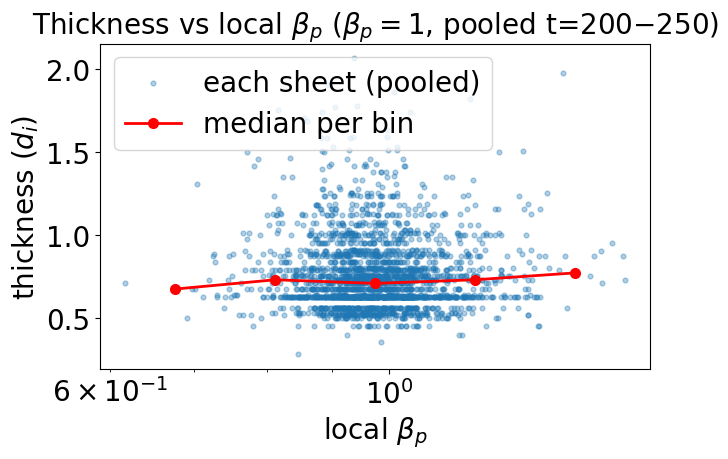


--- overall (pooled) statistics ---
local beta_p : median = 0.970, mean = 0.982
thickness    : median = 0.707, mean = 0.760 d_i

Everything saved in:  cs_beta_pooled_beta1_t200-250/


In [5]:
# %% ==========================================================================
#  CELL 2 — PLOTTING  (re-run as often as you like; no recomputation)
# ============================================================================
#  Uses CELL 1's in-memory arrays. If the kernel was restarted, it transparently
#  reloads them from pooled_beta_thickness.npz instead of recomputing.
# ============================================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
    'figure.titlesize': 20
})

# --- must match CELL 1 (used for titles + to locate the saved data) ---
beta    = 1
times   = list(range(200, 251, 5))
out_dir = str(RESULTS / f"cs_beta_pooled_beta{beta}_t{times[0]}-{times[-1]}")

# --- plotting parameters (tweak these, then re-run THIS cell only) ---
N_BINS = 5                              # number of local-beta_p bins for the medians

# --- get the pooled data: prefer CELL 1's arrays, else reload from disk ---
try:
    thickness
except NameError:
    print("pooled arrays not in memory -> loading from disk ...", flush=True)
    d = np.load(f"{out_dir}/pooled_beta_thickness.npz")
    times_arr = d["time"]; thickness = d["thickness_di"]; local_beta_p = d["local_beta_p"]


# ============================================================
# Histogram of pooled local proton beta
# ============================================================
plt.figure(figsize=(7, 5))
plt.hist(local_beta_p,
         bins=np.logspace(np.log10(local_beta_p.min()), np.log10(local_beta_p.max()), 30),
         alpha=0.6, edgecolor="black")
plt.axvline(np.median(local_beta_p), color="black", linestyle="--",
            label=f"median = {np.median(local_beta_p):.3f}")
plt.axvline(beta, color="red", linestyle=":", label=f"nominal = {beta}")
plt.xscale("log")
plt.xlabel(r"local $\beta_p$ around current sheet")
plt.ylabel("number of sheets (pooled)")
plt.title(rf"Local $\beta_p$ ($\beta_p={beta}$, pooled t={times[0]}$-${times[-1]}, N={len(local_beta_p)})")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_local_beta.png", dpi=300)
plt.show()


# ============================================================
# beta_p vs thickness: per-sheet table, summary table, scatter
# ============================================================
# per-sheet table (with the snapshot time)
with open(f"{out_dir}/beta_vs_thickness.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["time", "thickness_di", "local_beta_p"])
    for i in range(len(thickness)):
        w.writerow([int(times_arr[i]), thickness[i], local_beta_p[i]])

# summary: split pooled sheets into beta_p bins, thickness in each
bin_edges = np.logspace(np.log10(local_beta_p.min()), np.log10(local_beta_p.max()), N_BINS + 1)
print("\n--- thickness statistics in beta_p bins (pooled) ---")
print(f"{'beta_p range':>20} {'N':>6} {'median thick (d_i)':>20} {'mean thick (d_i)':>18}")
summary_rows = []
bin_centres, bin_med_thick = [], []
for i in range(len(bin_edges) - 1):
    lo, hi = bin_edges[i], bin_edges[i + 1]
    sel = (local_beta_p >= lo) & (local_beta_p < hi)
    if sel.sum() == 0:
        continue
    med_t, mean_t = np.median(thickness[sel]), np.mean(thickness[sel])
    print(f"{lo:7.3f}-{hi:7.3f} {sel.sum():>6} {med_t:>20.3f} {mean_t:>18.3f}")
    summary_rows.append([lo, hi, int(sel.sum()), med_t, mean_t])
    bin_centres.append(np.sqrt(lo * hi))
    bin_med_thick.append(med_t)

with open(f"{out_dir}/beta_thickness_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["beta_p_lo", "beta_p_hi", "n_sheets", "median_thickness_di", "mean_thickness_di"])
    w.writerows(summary_rows)

# scatter of thickness vs local beta_p, with binned medians on top
plt.figure(figsize=(7, 5))
plt.scatter(local_beta_p, thickness, s=12, alpha=0.35, label="each sheet (pooled)")
plt.plot(bin_centres, bin_med_thick, "o-", color="red", lw=2, ms=7, label="median per bin")
plt.xscale("log")
plt.xlabel(r"local $\beta_p$")
plt.ylabel(r"thickness $(d_i)$")
plt.title(rf"Thickness vs local $\beta_p$ ($\beta_p={beta}$, pooled t={times[0]}$-${times[-1]})")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_beta.png", dpi=300)
plt.show()

# ---- final numbers ----
print("\n--- overall (pooled) statistics ---")
print(f"local beta_p : median = {np.median(local_beta_p):.3f}, mean = {np.mean(local_beta_p):.3f}")
print(f"thickness    : median = {np.median(thickness):.3f}, mean = {np.mean(thickness):.3f} d_i")
print(f"\nEverything saved in:  {out_dir}/")

In [6]:
# %% ==========================================================================
#  CELL 1 — COMPUTATION  (run ONCE; heavy parallel analysis + pooling)
# ============================================================================
#  Current sheets: thickness vs LOCAL PROTON beta  --  beta_p scan
#  electron beta FIXED at 1, proton beta varied; ALL runs pooled.
#  (Mirror of the electron-beta script, with the beta_p <-> beta_e roles swapped.)
#
#  Because beta_e is fixed, it is the local PROTON beta that scales with the run,
#  so local beta_p is the informative x-axis here. Per sheet we record the
#  thickness and the local proton beta (median over a rectangle around the sheet).
#  Local beta_p is built from the proton pressures (Ppar1/Pper1).
#
#  Produces the in-memory arrays used by CELL 2 (also saved to pooled_all.npz):
#     run_beta_p, snap_time, thickness, local_beta_p
#  Re-run this cell only when the data or detection settings change.
#
#  Needs from your session: iterative_filtering3D, partial_x_fft,
#                           partial_y_fft, detect_current_sheets
# ============================================================================

import os
import csv
import numpy as np
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

# -----------------------------
# SETTINGS
# -----------------------------
BETA_E    = 1                              # electron beta -- FIXED
BETAS_P   = [0.0625, 0.25, 1, 4, 16]       # proton-beta runs to pool together
TIMES     = list(range(200, 251, 5))
sim_tag   = "ApJ"
base_root = str(DATA_ROOT)

cache_dir = str(CACHE / "filtered_cache_Jz")
out_dir   = str(RESULTS / f"cs_betap_scan_pooled_be{BETA_E}_t{TIMES[0]}-{TIMES[-1]}")

px_per_di = 16.0
box_pad   = 5
dx = dy   = 0.0625

P_PAR_TAG = "Ppar1"                        # proton parallel  pressure tag
P_PER_TAG = "Pper1"                        # proton perpendicular pressure tag

THREADS_PER_WORKER = 1

# detection parameters vary with beta_p (proton scale changes with beta_p)
FILTER_PARAMS_BETA_P = {
    0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0),
}

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)


def filter_params(beta_p):
    return FILTER_PARAMS_BETA_P[beta_p]


def base_path(beta_p):
    return f"{base_root}/beta_p_{beta_p}/beta_e_{BETA_E}/"


def load(tag, beta_p, time):
    with h5py.File(f"{base_path(beta_p)}{tag}_{sim_tag}_t{time}.h5", "r") as f:
        return f["DS1"][:].T


def _init_worker(n_threads):
    try:
        from threadpoolctl import threadpool_limits
        threadpool_limits(n_threads)
    except Exception:
        pass


# ============================================================
# One (beta_p, time) snapshot
#   -> (beta_p, time, thickness_di[], local_beta_p[])
# ============================================================
def analyze_snapshot(beta_p, time):
    Bx, By, Bz = load("Bx", beta_p, time), load("By", beta_p, time), load("Bz", beta_p, time)
    B2 = Bx**2 + By**2 + Bz**2

    # proton beta field (kinetic pressure moments)
    P_par  = load(P_PAR_TAG, beta_p, time)
    P_perp = load(P_PER_TAG, beta_p, time)
    P_scalar = (P_par + 2.0 * P_perp) / 3.0
    beta_p_field = 2.0 * P_scalar / B2

    # --- detect sheets (filtered B, cached; keyed by beta_p) ---
    n_iter, Xi = filter_params(beta_p)
    cache_file = f"{cache_dir}/filtered_beta_{beta_p}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache_file):
        d = np.load(cache_file)
        Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        Bx_f, By_f, Bz_f = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache_file, Bx=Bx_f, By=By_f, Bz=Bz_f)

    Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    mask = morphology.remove_small_objects(mask.astype(bool), min_size=500).astype(int)

    labeled = measure.label(mask, connectivity=2)
    n_sheets = labeled.max()
    all_sheets_mask = labeled > 0

    thick, lbeta_p = [], []
    for k in range(1, n_sheets + 1):
        region = (labeled == k)

        dist = ndi.distance_transform_edt(region)
        thick_di = (2 * dist.max()) / px_per_di

        xs_r, ys_r = np.where(region)
        bx0 = max(0, xs_r.min() - box_pad)
        bx1 = min(B2.shape[0], xs_r.max() + box_pad + 1)
        by0 = max(0, ys_r.min() - box_pad)
        by1 = min(B2.shape[1], ys_r.max() + box_pad + 1)
        box_region = np.zeros_like(region)
        box_region[bx0:bx1, by0:by1] = True
        box_region = box_region & ~all_sheets_mask
        if box_region.sum() < 20:
            continue

        thick.append(thick_di)
        lbeta_p.append(float(np.median(beta_p_field[box_region])))

    return beta_p, time, np.array(thick), np.array(lbeta_p)


# ============================================================
# Run every (beta_p, time) in parallel, pool EVERYTHING
# ============================================================
tasks = [(bp, t) for bp in BETAS_P for t in TIMES]
n_workers = min(len(tasks), os.cpu_count() or 1)

run_beta_p, snap_time, thickness, local_beta_p = [], [], [], []

def _store(res):
    bp, t, th, lbp = res
    run_beta_p.extend([bp] * len(th))
    snap_time.extend([t] * len(th))
    thickness.extend(th)
    local_beta_p.extend(lbp)
    print(f"beta_p={bp}, t={t}: {len(th)} sheets", flush=True)

if n_workers == 1:
    for bp, t in tasks:
        try:
            _store(analyze_snapshot(bp, t))
        except FileNotFoundError:
            print(f"beta_p={bp}, t={t}: missing file, skipped", flush=True)
else:
    ctx = mp.get_context("fork")
    print(f"Analysing {len(tasks)} (beta_p,time) snapshots across {n_workers} workers ...", flush=True)
    with ProcessPoolExecutor(max_workers=n_workers, mp_context=ctx,
                             initializer=_init_worker, initargs=(THREADS_PER_WORKER,)) as ex:
        futs = {ex.submit(analyze_snapshot, bp, t): (bp, t) for bp, t in tasks}
        for fut in as_completed(futs):
            bp, t = futs[fut]
            try:
                _store(fut.result())
            except FileNotFoundError:
                print(f"beta_p={bp}, t={t}: missing file, skipped", flush=True)

run_beta_p   = np.array(run_beta_p)
snap_time    = np.array(snap_time)
thickness    = np.array(thickness)
local_beta_p = np.array(local_beta_p)
print(f"\npooled {len(thickness)} sheets total (all beta_p runs, all snapshots)", flush=True)
if len(thickness) == 0:
    raise SystemExit("No sheets pooled (check paths/times).")

np.savez_compressed(f"{out_dir}/pooled_all.npz",
                    beta_p=run_beta_p, time=snap_time, thickness_di=thickness,
                    local_beta_p=local_beta_p)
with open(f"{out_dir}/pooled_all.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["beta_p", "time", "thickness_di", "local_beta_p"])
    for i in range(len(thickness)):
        w.writerow([run_beta_p[i], int(snap_time[i]), thickness[i], local_beta_p[i]])
print(f"saved pooled data -> {out_dir}/pooled_all.npz (+ .csv)", flush=True)

Analysing 55 (beta_p,time) snapshots across 55 workers ...
beta_p=16, t=225: 79 sheets
beta_p=16, t=245: 99 sheets
beta_p=16, t=240: 100 sheets
beta_p=16, t=250: 100 sheets
beta_p=16, t=235: 102 sheets
beta_p=16, t=205: 105 sheets
beta_p=16, t=210: 106 sheets
beta_p=16, t=230: 108 sheets
beta_p=16, t=220: 109 sheets
beta_p=16, t=200: 111 sheets
beta_p=16, t=215: 113 sheets
beta_p=4, t=250: 137 sheets
beta_p=4, t=240: 158 sheets
beta_p=4, t=235: 164 sheets
beta_p=4, t=245: 165 sheets
beta_p=4, t=230: 167 sheets
beta_p=4, t=200: 177 sheets
beta_p=4, t=225: 180 sheets
beta_p=4, t=215: 180 sheets
beta_p=4, t=210: 182 sheets
beta_p=4, t=205: 185 sheets
beta_p=4, t=220: 187 sheets
beta_p=1, t=245: 197 sheets
beta_p=1, t=250: 205 sheets
beta_p=1, t=235: 206 sheets
beta_p=1, t=220: 208 sheets
beta_p=1, t=230: 212 sheets
beta_p=0.25, t=230: 212 sheets
beta_p=1, t=240: 214 sheets
beta_p=0.25, t=225: 210 sheets
beta_p=1, t=225: 215 sheets
beta_p=0.25, t=250: 217 sheets
beta_p=0.25, t=245: 219 she

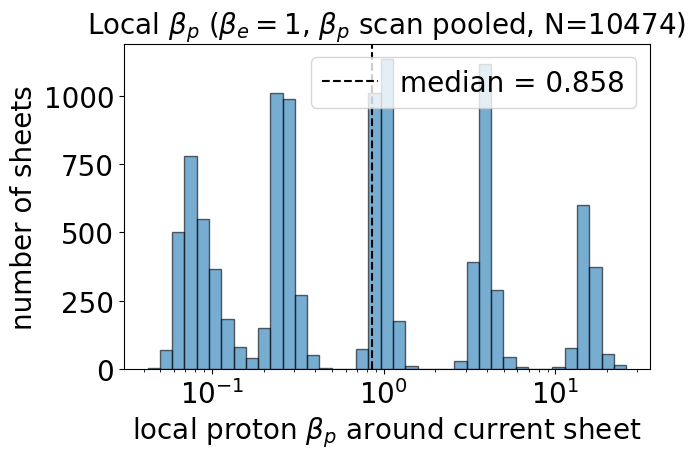

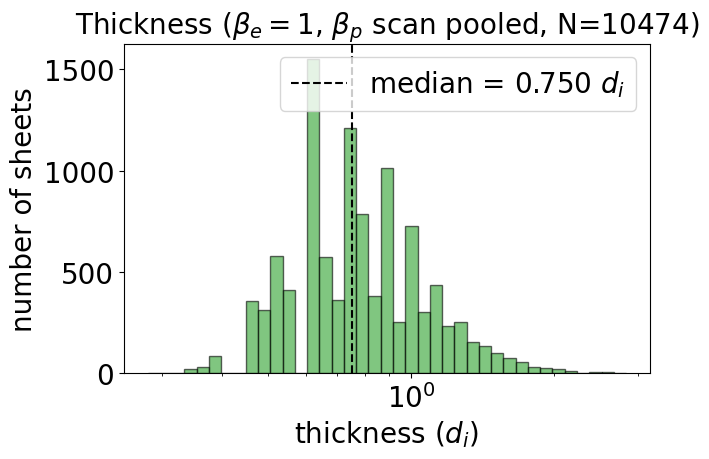

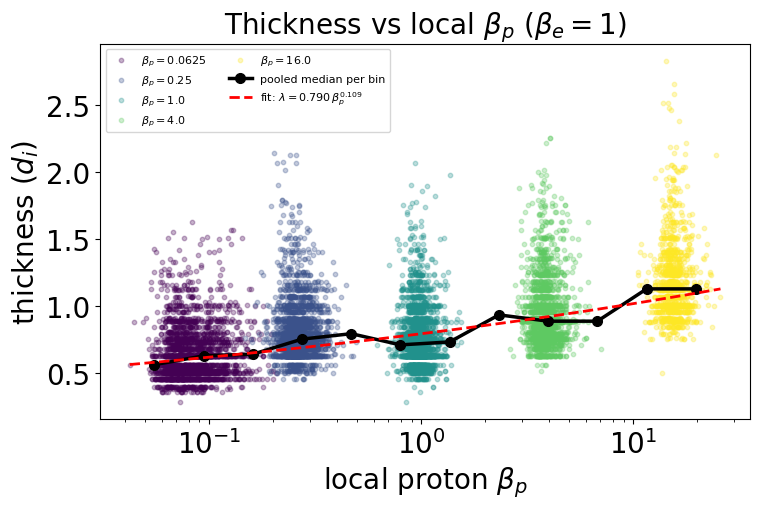

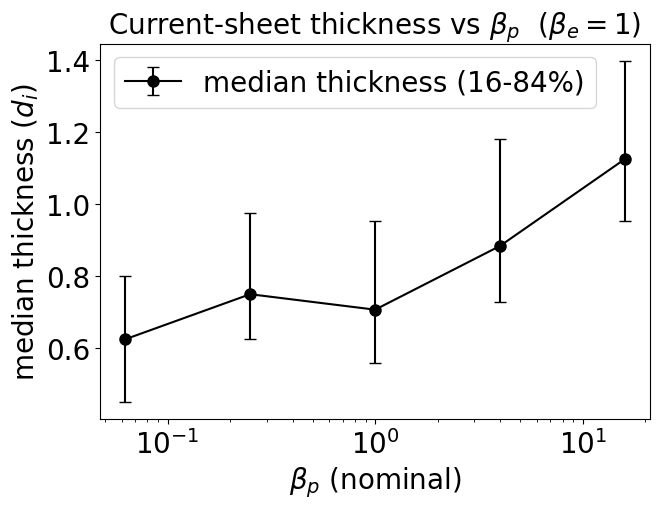


--- pooled sample ---
total sheets              : 10474
local beta_p : median = 0.858  (range 0.0422-25.8)
thickness    : median = 0.750 d_i
power-law fit             : lambda = 0.790 * beta_p_local^0.109
Spearman rho (thick, beta_p_local): 0.541  (p=0)

--- per-run summary (beta_e = 1 fixed) ---
  beta_p       N    med thick   med local bp
  0.0625    2569        0.625          0.080
    0.25    2482        0.750          0.260
     1.0    2409        0.707          0.970
     4.0    1882        0.884          3.833
    16.0    1132        1.125         15.353

Everything saved in:  cs_betap_scan_pooled_be1_t200-250/


In [8]:
# %% ==========================================================================
#  CELL 2 — PLOTTING  (re-run as often as you like; no recomputation)
# ============================================================================
#  Uses CELL 1's in-memory arrays. If the kernel was restarted, it transparently
#  reloads them from pooled_all.npz instead of recomputing.
# ============================================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# --- must match CELL 1 (used for titles + to locate the saved data) ---
BETA_E  = 1
TIMES   = list(range(200, 251, 5))
out_dir = str(RESULTS / f"cs_betap_scan_pooled_be{BETA_E}_t{TIMES[0]}-{TIMES[-1]}")

# --- plotting parameters (tweak these, then re-run THIS cell only) ---
N_BINS_MED  = 12
MIN_PER_BIN = 10

# --- get the pooled data: prefer CELL 1's arrays, else reload from disk ---
try:
    thickness
except NameError:
    print("pooled arrays not in memory -> loading from disk ...", flush=True)
    d = np.load(f"{out_dir}/pooled_all.npz")
    run_beta_p   = d["beta_p"]; snap_time = d["time"]
    thickness    = d["thickness_di"]; local_beta_p = d["local_beta_p"]

present = sorted(np.unique(run_beta_p).tolist())   # proton-beta runs actually present


# ============================================================
# Pooled distributions (local proton beta + thickness)
# ============================================================
plt.figure(figsize=(7, 5))
plt.hist(local_beta_p,
         bins=np.logspace(np.log10(local_beta_p.min()), np.log10(local_beta_p.max()), 40),
         alpha=0.6, edgecolor="black")
plt.axvline(np.median(local_beta_p), color="black", linestyle="--",
            label=f"median = {np.median(local_beta_p):.3f}")
plt.xscale("log")
plt.xlabel(r"local proton $\beta_p$ around current sheet"); plt.ylabel("number of sheets")
plt.title(rf"Local $\beta_p$ ($\beta_e={BETA_E}$, $\beta_p$ scan pooled, N={len(local_beta_p)})")
plt.legend(); plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_local_betap_pooled.png", dpi=300); plt.show()

plt.figure(figsize=(7, 5))
plt.hist(thickness,
         bins=np.logspace(np.log10(thickness.min()), np.log10(thickness.max()), 40),
         alpha=0.6, edgecolor="black", color="tab:green")
plt.axvline(np.median(thickness), color="black", linestyle="--",
            label=f"median = {np.median(thickness):.3f} $d_i$")
plt.xscale("log")
plt.xlabel(r"thickness $(d_i)$"); plt.ylabel("number of sheets")
plt.title(rf"Thickness ($\beta_e={BETA_E}$, $\beta_p$ scan pooled, N={len(thickness)})")
plt.legend(); plt.tight_layout()
plt.savefig(f"{out_dir}/histogram_thickness_pooled.png", dpi=300); plt.show()


# ============================================================
# Thickness vs local PROTON beta (pooled) + power-law fit
# ============================================================
edges = np.logspace(np.log10(local_beta_p.min()), np.log10(local_beta_p.max()), N_BINS_MED + 1)
cen, med, cnt = [], [], []
summary_rows = []
for i in range(N_BINS_MED):
    lo, hi = edges[i], edges[i + 1]
    sel = (local_beta_p >= lo) & (local_beta_p < hi)
    if sel.sum() == 0:
        continue
    cen.append(np.sqrt(lo * hi)); med.append(np.median(thickness[sel])); cnt.append(int(sel.sum()))
    summary_rows.append([lo, hi, int(sel.sum()),
                         np.median(thickness[sel]), np.mean(thickness[sel])])
cen, med, cnt = np.array(cen), np.array(med), np.array(cnt)

with open(f"{out_dir}/binned_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["local_betap_lo", "local_betap_hi", "n_sheets",
                "median_thickness_di", "mean_thickness_di"])
    w.writerows(summary_rows)

fit_ok = cnt >= MIN_PER_BIN
a = b = np.nan
if fit_ok.sum() >= 2:
    b, logA = np.polyfit(np.log10(cen[fit_ok]), np.log10(med[fit_ok]), 1)
    a = 10 ** logA

rho, pval = spearmanr(local_beta_p, thickness)

colors = {bp: plt.cm.viridis(i / max(1, len(present) - 1)) for i, bp in enumerate(present)}

plt.figure(figsize=(8, 5.5))
for bp in present:
    m = run_beta_p == bp
    plt.scatter(local_beta_p[m], thickness[m], s=10, alpha=0.30,
                color=colors[bp], label=fr"$\beta_p={bp}$")
plt.plot(cen, med, "o-", color="black", lw=2.5, ms=7, label="pooled median per bin")
if np.isfinite(b):
    xx = np.logspace(np.log10(local_beta_p.min()), np.log10(local_beta_p.max()), 60)
    plt.plot(xx, a * xx**b, "--", color="red", lw=2,
             label=fr"fit: $\lambda = {a:.3f}\,\beta_p^{{{b:.3f}}}$")
plt.xscale("log")
plt.xlabel(r"local proton $\beta_p$"); plt.ylabel(r"thickness $(d_i)$")
plt.title(rf"Thickness vs local $\beta_p$ ($\beta_e={BETA_E}$)")
plt.legend(fontsize=8, ncol=2); plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_local_betap_pooled.png", dpi=300); plt.show()


# ============================================================
# Thickness vs nominal beta_p (per-run medians)
# ============================================================
bp_arr  = np.array(present, float)
med_th  = np.array([np.median(thickness[run_beta_p == bp]) for bp in present])
th_lo   = np.array([np.percentile(thickness[run_beta_p == bp], 16) for bp in present])
th_hi   = np.array([np.percentile(thickness[run_beta_p == bp], 84) for bp in present])
med_lbp = np.array([np.median(local_beta_p[run_beta_p == bp]) for bp in present])

plt.figure(figsize=(7, 5.5))
plt.errorbar(bp_arr, med_th, yerr=[med_th - th_lo, th_hi - med_th],
             fmt="o-", ms=8, capsize=4, color="k", label="median thickness (16-84%)")
plt.xscale("log")
plt.xlabel(r"$\beta_p$ (nominal)"); plt.ylabel(r"median thickness $(d_i)$")
plt.title(rf"Current-sheet thickness vs $\beta_p$  ($\beta_e={BETA_E}$)")
plt.legend(); plt.tight_layout()
plt.savefig(f"{out_dir}/thickness_vs_betap.png", dpi=300); plt.show()

with open(f"{out_dir}/per_betap_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["beta_p", "n_sheets", "median_thickness_di", "thick_16", "thick_84",
                "median_local_beta_p"])
    for i, bp in enumerate(present):
        w.writerow([bp, int(np.sum(run_beta_p == bp)), med_th[i], th_lo[i], th_hi[i], med_lbp[i]])


# ============================================================
# Summary
# ============================================================
print("\n--- pooled sample ---")
print(f"total sheets              : {len(thickness)}")
print(f"local beta_p : median = {np.median(local_beta_p):.3f}  (range {local_beta_p.min():.3g}-{local_beta_p.max():.3g})")
print(f"thickness    : median = {np.median(thickness):.3f} d_i")
if np.isfinite(b):
    print(f"power-law fit             : lambda = {a:.3f} * beta_p_local^{b:.3f}")
print(f"Spearman rho (thick, beta_p_local): {rho:.3f}  (p={pval:.2g})")

print("\n--- per-run summary (beta_e = 1 fixed) ---")
print(f"{'beta_p':>8} {'N':>7} {'med thick':>12} {'med local bp':>14}")
for i, bp in enumerate(present):
    print(f"{bp:>8} {int(np.sum(run_beta_p == bp)):>7} {med_th[i]:>12.3f} {med_lbp[i]:>14.3f}")
print(f"\nEverything saved in:  {out_dir}/")